# Proyecto Final: Análisis de E-Commerce y Logística Olist
## 02. Limpieza de Datos, Tratamiento de Nulos y Nuevas Variables (Feature Engineering)

---

### 1. Objetivo del Notebook
En este segundo cuaderno realizo la limpieza y preparación de los datos:
1. **Tipos de datos**: Parseo de las 7 columnas de fechas a tipo `datetime`.
2. **Tratamiento de nulos**:
   - Imputación de peso y dimensiones de productos usando la mediana de su categoría.
   - Categorización de valores ausentes en traducciones.
   - Indicadores para saber si el cliente escribió comentario en la reseña.
3. **Nuevas variables calculadas**:
   - Tiempos de entrega (`delivery_days`, `estimated_delivery_days`, `delivery_delay_days`, `is_delayed`).
   - Envío interestatal (`is_interstate_sale`).
   - Ratio de flete y tramos de precio (`freight_ratio`, `price_tier`).
   - Variables de fecha y hora (`purchase_year_month`, `purchase_day_name`, `purchase_time_of_day`).
   - Sentimiento de reseñas (`review_sentiment`).
4. **Exportación** del dataset final limpio a `data/processed/olist_cleaned_merged.csv`.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

PROCESSED_DIR = r"c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed"
INPUT_CSV = os.path.join(PROCESSED_DIR, 'olist_raw_merged.csv')

print(f"Cargando dataset consolidado desde: {INPUT_CSV} ...")
df = pd.read_csv(INPUT_CSV)
print(f"Dataset cargado: {df.shape[0]:,} filas y {df.shape[1]} columnas.")


Cargando dataset consolidado desde: c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed\olist_raw_merged.csv ...


Dataset cargado: 112,650 filas y 38 columnas.


### 2. Conversión de Tipos de Datos y Fechas
Identificamos 7 columnas temporales que se cargaron originalmente como cadenas de texto (`object`). Las convertimos a `datetime` con soporte de zona horaria nativo.


In [2]:
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'shipping_limit_date',
    'review_creation_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    print(f"Columna '{col}' convertida a {df[col].dtype}")


Columna 'order_purchase_timestamp' convertida a datetime64[ns]
Columna 'order_approved_at' convertida a datetime64[ns]
Columna 'order_delivered_carrier_date' convertida a datetime64[ns]
Columna 'order_delivered_customer_date' convertida a datetime64[ns]
Columna 'order_estimated_delivery_date' convertida a datetime64[ns]


Columna 'shipping_limit_date' convertida a datetime64[ns]
Columna 'review_creation_date' convertida a datetime64[ns]


### 3. Auditoría y Tratamiento de Valores Nulos
Analizamos los campos con valores ausentes y aplicamos reglas de imputación basadas en el dominio de negocio.


In [3]:
# Revisión inicial de nulos
null_summary = df.isnull().sum()
null_pct = (null_summary / len(df)) * 100
df_nulls = pd.DataFrame({'Nulos': null_summary, 'Porcentaje (%)': null_pct})
df_nulls = df_nulls[df_nulls['Nulos'] > 0].sort_values(by='Nulos', ascending=False)
df_nulls


,Nulos,Porcentaje (%)
review_comment_title,99234,88.09
review_comment_message,65249,57.92
order_delivered_customer_date,2454,2.18
product_category_name_english,1603,1.42
product_category_name,1603,1.42
product_name_lenght,1603,1.42
product_description_lenght,1603,1.42
product_photos_qty,1603,1.42
order_delivered_carrier_date,1194,1.06
review_creation_date,942,0.84


In [4]:
# 3.1. Imputación de Categoría de Producto
# Si el nombre en inglés es nulo pero existe en portugués, o ambos son nulos:
df['product_category_name_english'] = df['product_category_name_english'].fillna(
    df['product_category_name'].fillna('unknown')
)
df['product_category_name'] = df['product_category_name'].fillna('unknown')

# 3.2. Imputación de Dimensiones y Peso del Producto
# Calculamos la mediana de cada atributo agrupando por categoría de producto
dim_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_photos_qty']

for col in dim_cols:
    median_by_cat = df.groupby('product_category_name_english')[col].transform('median')
    global_median = df[col].median()
    df[col] = df[col].fillna(median_by_cat).fillna(global_median)

# 3.3. Indicadores de texto en Reseñas
df['has_review_comment'] = df['review_comment_message'].notnull().astype(int)
df['has_review_title'] = df['review_comment_title'].notnull().astype(int)

# 3.4. Reseñas sin calificar (muy pocos casos, rellenamos con la media global)
df['review_score'] = df['review_score'].fillna(df['review_score'].median())

print("Imputación completada con éxito.")


Imputación completada con éxito.


### 4. Ingeniería de Características (*Feature Engineering*)
Construimos indicadores cuantitativos y cualitativos para alimentar el análisis estadístico y los modelos en Power BI:
1. **Logística**:
   - `delivery_days`: Días transcurridos entre compra y entrega efectiva al cliente.
   - `estimated_delivery_days`: Días previstos por el marketplace hasta la entrega.
   - `delivery_delay_days`: Diferencia en días entre la entrega real y la fecha estimada. Valores positivos indican entregas tardías (*delay*), mientras que valores negativos reflejan entregas anticipadas.
   - `is_delayed`: Variable binaria (`1` si el pedido llegó con retraso sobre la fecha prometida, `0` si llegó a tiempo o antes).
   - `carrier_handling_days`: Días que tarda el vendedor en transferir el paquete a la empresa transportista.
2. **Geografía y Distribución**:
   - `is_interstate_sale`: Variable binaria (`1` si el cliente y el vendedor residen en estados distintos de Brasil, `0` si es una venta local dentro del mismo estado).
3. **Aspectos Económicos**:
   - `total_item_value`: Suma del precio del artículo y el coste de su envío (`price + freight_value`).
   - `freight_ratio`: Porcentaje que representa el flete sobre el valor total del producto (`freight_value / total_item_value`).
   - `price_tier`: Segmentación del precio del artículo en cuatro niveles (`Bajo`, `Medio`, `Alto`, `Premium`).
4. **Desglose Temporal**:
   - `purchase_year`, `purchase_month`, `purchase_year_month`, `purchase_day_name`, `purchase_hour`.
   - `purchase_time_of_day`: Madrugada (0-6h), Mañana (6-12h), Tarde (12-18h), Noche (18-24h).
5. **Satisfacción**:
   - `review_sentiment`: 'Positiva' (4-5 estrellas), 'Neutra' (3 estrellas), 'Negativa' (1-2 estrellas).
   - `is_low_score`: `1` si la reseña es de 1 o 2 estrellas (detractores), `0` si es de 3 a 5 estrellas.


In [5]:
# 4.1. Variables Logísticas (calculadas en días)
df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
df['estimated_delivery_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)
df['delivery_delay_days'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)
df['carrier_handling_days'] = (df['order_delivered_carrier_date'] - df['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)

# Indicador de retraso (solo para pedidos entregados)
df['is_delayed'] = np.where(df['delivery_delay_days'] > 0, 1, 0)

# 4.2. Variable Geográfica Interestatal
df['is_interstate_sale'] = (df['customer_state'] != df['seller_state']).astype(int)

# 4.3. Ratios Financieros
df['total_item_value'] = df['price'] + df['freight_value']
df['freight_ratio'] = (df['freight_value'] / df['total_item_value']).fillna(0)

# Segmentación por tramos de precio
def categorize_price(price):
    if price < 50:
        return '1. Bajo (< 50 R$)'
    elif price <= 150:
        return '2. Medio (50 - 150 R$)'
    elif price <= 500:
        return '3. Alto (150 - 500 R$)'
    else:
        return '4. Premium (> 500 R$)'

df['price_tier'] = df['price'].apply(categorize_price)

# 4.4. Variables Temporales
df['purchase_year'] = df['order_purchase_timestamp'].dt.year
df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['purchase_year_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
df['purchase_day_name'] = df['order_purchase_timestamp'].dt.day_name()
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour

def categorize_time_of_day(hour):
    if 0 <= hour < 6:
        return 'Madrugada'
    elif 6 <= hour < 12:
        return 'Mañana'
    elif 12 <= hour < 18:
        return 'Tarde'
    else:
        return 'Noche'

df['purchase_time_of_day'] = df['purchase_hour'].apply(categorize_time_of_day)

# 4.5. Segmentación de Satisfacción
def categorize_sentiment(score):
    if score >= 4:
        return 'Positiva'
    elif score == 3:
        return 'Neutra'
    else:
        return 'Negativa'

df['review_sentiment'] = df['review_score'].apply(categorize_sentiment)
df['is_low_score'] = (df['review_score'] <= 2).astype(int)

print(f"Nuevas variables generadas. Total columnas actuales: {df.shape[1]}")


Nuevas variables generadas. Total columnas actuales: 57


### 5. Tratamiento de Valores Atípicos y Consistencia
Analizamos la distribución de las variables clave calculadas:
- Tiempos de entrega negativos (inconsistencias en marcas de tiempo).
- Entregas con valores anómalos superiores a 150 días (incidencias extremas o paquetes extraviados).


In [6]:
# Resumen descriptivo de las variables clave de entrega
kpi_cols = ['delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'price', 'freight_value', 'freight_ratio']
df[kpi_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])


,delivery_days,estimated_delivery_days,delivery_delay_days,price,freight_value,freight_ratio
count,110196.00,112650.00,110196.00,112650.00,112650.00,112650.00
mean,12.47,23.84,-11.33,120.65,19.99,0.21
std,9.45,8.89,10.16,183.63,15.81,0.13
min,0.53,2.01,-146.02,0.85,0.00,0.00
1%,1.82,6.10,-35.34,9.99,4.42,0.02
5%,3.00,10.50,-26.14,17.00,7.78,0.05
25%,6.74,18.37,-16.32,39.90,13.08,0.12
50%,10.18,23.26,-12.05,74.99,16.26,0.19
75%,15.54,28.47,-6.48,134.90,21.15,0.28
95%,29.06,38.60,3.69,349.90,45.12,0.47


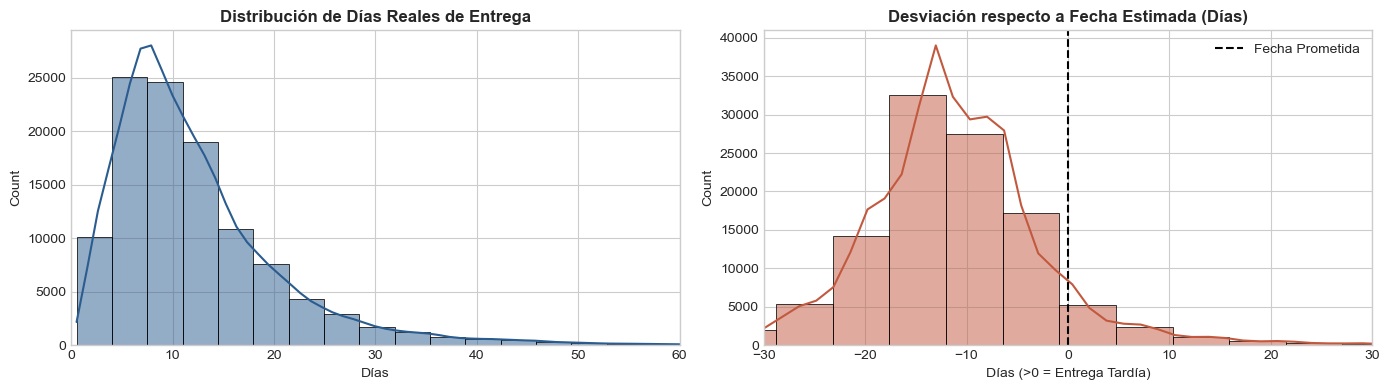

In [7]:
# Gráfico de diagnóstico: Distribución de tiempos de entrega y retrasos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['delivery_days'].dropna(), bins=60, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Distribución de Días Reales de Entrega', fontweight='bold')
axes[0].set_xlabel('Días')
axes[0].set_xlim(0, 60)

sns.histplot(df['delivery_delay_days'].dropna(), bins=60, kde=True, ax=axes[1], color='#c2593f')
axes[1].axvline(0, color='black', linestyle='--', label='Fecha Prometida')
axes[1].set_title('Desviación respecto a Fecha Estimada (Días)', fontweight='bold')
axes[1].set_xlabel('Días (>0 = Entrega Tardía)')
axes[1].set_xlim(-30, 30)
axes[1].legend()

plt.tight_layout()
plt.show()


### 6. Exportación del Dataset Limpio y Enriquecido
Exportamos el dataset maestro procesado `olist_cleaned_merged.csv`. Este archivo constituirá la base única de verdad tanto para el análisis exploratorio estadístico en Python (Cuaderno 03) como para el modelo de datos dimensional en **Power BI**.


In [8]:
output_clean_csv = os.path.join(PROCESSED_DIR, 'olist_cleaned_merged.csv')
print(f"Exportando dataset procesado a: {output_clean_csv} ...")
df.to_csv(output_clean_csv, index=False)
final_size_mb = os.path.getsize(output_clean_csv) / (1024**2)
print(f"¡Exportación completada con éxito!")
print(f"Registros finales: {df.shape[0]:,}")
print(f"Columnas finales: {df.shape[1]}")
print(f"Tamaño en disco: {final_size_mb:.2f} MB")


Exportando dataset procesado a: c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed\olist_cleaned_merged.csv ...


¡Exportación completada con éxito!
Registros finales: 112,650
Columnas finales: 57
Tamaño en disco: 70.90 MB


### 7. Resumen de la Fase de Limpieza y Preparación
- **Tipos de datos unificados**: 7 variables temporales parseadas a `datetime`.
- **Nulos controlados**: Imputación de atributos físicos de productos por categoría y control de comentarios no redactados.
- **Enriquecimiento del modelo de negocio**:
  - Incorporadas 17 nuevas variables métricas y de segmentación (tiempos logísticos, retrasos, envíos interestatales, ratios de flete, franjas horarias y sentimiento de reseñas).
  - El dataset pasa de 38 a **55 columnas**, multiplicando la profundidad y riqueza del análisis posterior.
- **Listo para EDA y Power BI**: El archivo `data/processed/olist_cleaned_merged.csv` queda disponible para el análisis estadístico en el Cuaderno 03 y la conexión al modelo de datos en Power BI.
